# NoSQL Databases & MongoDB Fundamentals

**NoSQL** databases store data in other models than tables: documents, key-value pairs, wide columns or graphs. **MongoDB**, the most popular document database, stores **JSON-like documents** that can nest objects and arrays. One document can hold what a relational database spreads over several tables.

**After this lesson you can:**

1. Compare the main NoSQL models with relational databases.
2. Insert, query, update and delete documents with `pymongo`.
3. Design documents: embedding vs referencing.
4. Analyse data with the aggregation pipeline and speed it up with indexes.

The lesson uses a real MongoDB server (Docker, profile `db`) and the real Chinook data in JSON form.

In [1]:
import sys
from pathlib import Path
import json
import time

import matplotlib.pyplot as plt
import pandas as pd
from pymongo import ASCENDING, MongoClient

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets

datasets.ensure_service("db", "mongodb")
client = MongoClient("mongodb://localhost:27017", serverSelectionTimeoutMS=20_000)
print("MongoDB server version:", client.server_info()["version"])
db = client["chinook"]

MongoDB server version: 8.3.17


## 1. NoSQL Models

| Model | Example systems | Data unit | Strength |
| :--- | :--- | :--- | :--- |
| **document** | MongoDB, Couchbase | JSON document | flexible, nested records |
| **key-value** | Redis, DynamoDB | value by key | very fast lookups (Lesson 13) |
| **wide-column** | Cassandra, ScyllaDB | rows with many columns | huge write volumes |
| **graph** | Neo4j | nodes and edges | relationship queries (M19) |
| **vector** | pgvector, Qdrant | embeddings | similarity search (Lesson 14, M28) |

Relational databases are still the default. Choose NoSQL for a specific need: very flexible schemas, extreme scale, or a data model (graph, key-value) that tables represent poorly.

## 2. Load Documents

`ChinookData.json` contains every Chinook table as a list of JSON objects. The cell builds **one document per invoice** and **embeds** the invoice lines (with track and genre names) into it.

In [2]:
raw = json.loads(datasets.fetch("chinook.json").read_text(encoding="utf-8"))
tracks = {t["TrackId"]: t for t in raw["Track"]}
genres = {g["GenreId"]: g["Name"] for g in raw["Genre"]}
customers = {c["CustomerId"]: c for c in raw["Customer"]}
lines_by_invoice: dict[int, list] = {}
for il in raw["InvoiceLine"]:
    t = tracks[il["TrackId"]]
    lines_by_invoice.setdefault(il["InvoiceId"], []).append(
        {"track": t["Name"], "genre": genres.get(t["GenreId"]), "unit_price": il["UnitPrice"], "quantity": il["Quantity"]})

docs = []
for inv in raw["Invoice"]:
    c = customers[inv["CustomerId"]]
    docs.append({"_id": inv["InvoiceId"], "date": inv["InvoiceDate"], "total": inv["Total"],
                 "customer": {"id": c["CustomerId"], "name": f"{c['FirstName']} {c['LastName']}", "country": c["Country"],
                              "email": c["Email"]},
                 "lines": lines_by_invoice.get(inv["InvoiceId"], [])})
db.invoices.drop()
db.invoices.insert_many(docs)
print(f"{db.invoices.count_documents({}):,} invoice documents")
print(json.dumps(db.invoices.find_one({}, {"_id": 1, "customer": 1, "total": 1, "lines": {"$slice": 2}}), indent=2, default=str)[:700])

412 invoice documents


{
  "_id": 1,
  "total": 1.98,
  "customer": {
    "id": 2,
    "name": "Leonie K\u00f6hler",
    "country": "Germany",
    "email": "leonekohler@surfeu.de"
  },
  "lines": [
    {
      "track": "Balls to the Wall",
      "genre": "Rock",
      "unit_price": 0.99,
      "quantity": 1
    },
    {
      "track": "Restless and Wild",
      "genre": "Rock",
      "unit_price": 0.99,
      "quantity": 1
    }
  ]
}


## 3. CRUD and Query Operators

| SQL | MongoDB |
| :--- | :--- |
| `SELECT ... WHERE country = 'Brazil'` | `find({"customer.country": "Brazil"})` |
| `WHERE total > 10` | `{"total": {"$gt": 10}}` |
| `WHERE country IN (...)` | `{"customer.country": {"$in": [...]}}` |
| `INSERT` | `insert_one`, `insert_many` |
| `UPDATE ... SET` | `update_many(filter, {"$set": {...}})` |
| `DELETE` | `delete_many(filter)` |

Dot notation (`"customer.country"`) queries nested fields; a condition on an array field matches if **any** element matches.

In [3]:
print("invoices from Brazil       :", db.invoices.count_documents({"customer.country": "Brazil"}))
print("invoices with total > 15   :", db.invoices.count_documents({"total": {"$gt": 15}}))
print("invoices with a Jazz track :", db.invoices.count_documents({"lines.genre": "Jazz"}))
big = list(db.invoices.find({"total": {"$gte": 20}}, {"_id": 1, "total": 1, "customer.name": 1}).sort("total", -1).limit(3))
print("largest invoices           :", big)

res = db.invoices.update_many({"customer.country": "Brazil"}, {"$set": {"region": "LATAM"}})
print("documents updated          :", res.modified_count)

invoices from Brazil       : 35
invoices with total > 15   : 11
invoices with a Jazz track : 41
largest invoices           : [{'_id': 404, 'total': 25.86, 'customer': {'name': 'Helena Holý'}}, {'_id': 299, 'total': 23.86, 'customer': {'name': 'Richard Cunningham'}}, {'_id': 96, 'total': 21.86, 'customer': {'name': 'Ladislav Kovács'}}]


documents updated          : 35


## 4. The Aggregation Pipeline

An aggregation is a **pipeline of stages**; each stage transforms the stream of documents:

| Stage | SQL equivalent |
| :--- | :--- |
| `$match` | `WHERE` |
| `$unwind` | turn each array element into its own document (a join with the embedded array) |
| `$group` | `GROUP BY` with accumulators (`$sum`, `$avg`, ...) |
| `$sort`, `$limit` | `ORDER BY`, `LIMIT` |
| `$project` | `SELECT` columns and expressions |
| `$lookup` | `LEFT JOIN` with another collection |

In [4]:
pipeline = [
    {"$unwind": "$lines"},
    {"$group": {"_id": "$lines.genre",
                "revenue": {"$sum": {"$multiply": ["$lines.unit_price", "$lines.quantity"]}},
                "countries": {"$addToSet": "$customer.country"}}},
    {"$project": {"revenue": {"$round": ["$revenue", 2]}, "n_countries": {"$size": "$countries"}}},
    {"$sort": {"revenue": -1}},
    {"$limit": 8},
]
genre_rev = pd.DataFrame(db.invoices.aggregate(pipeline)).rename(columns={"_id": "genre"})
genre_rev

,genre,revenue,n_countries
0,Rock,826.65,24
1,Latin,382.14,23
2,Metal,261.36,22
3,Alternative & Punk,241.56,22
4,TV Shows,93.53,12
5,Jazz,79.20,15
6,Blues,60.39,15
7,Drama,57.71,10


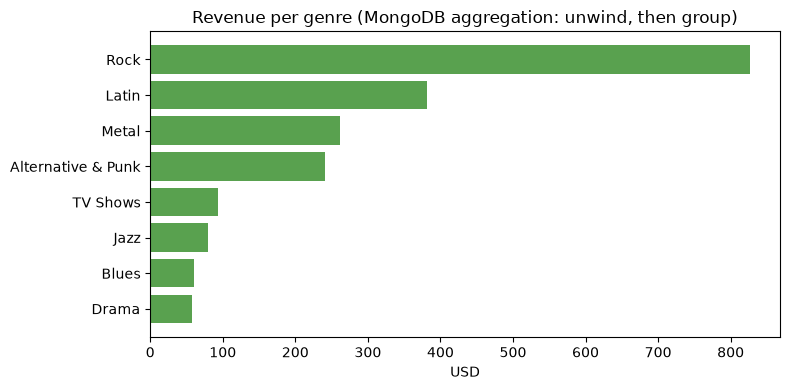

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(genre_rev["genre"][::-1], genre_rev["revenue"][::-1], color="#59A14F")
ax.set(title="Revenue per genre (MongoDB aggregation: unwind, then group)", xlabel="USD")
plt.tight_layout()
plt.show()

The result equals the SQL query with joins in Lesson 06, but here the genre data was embedded in each invoice, so no join is needed at query time.

## 5. Embedding vs Referencing, and Indexes

- **Embed** data that is read together and owned by the parent (invoice lines inside an invoice).
- **Reference** data that is shared or changes independently (a customer's address used by many invoices). Embedding copies it, with the update problems of Lesson 02.

Without an index, a query scans every document (`COLLSCAN`). The experiment inserts 200,000 documents and compares a query before and after creating an index, using `explain()`.

In [6]:
import random

random.seed(0)
db.events.drop()
db.events.insert_many([{"user": random.randint(1, 20_000), "kind": random.choice(["view", "click", "buy"]),
                        "value": random.random()} for _ in range(200_000)])

def run_query():
    t = time.perf_counter()
    plan = db.events.find({"user": 4242}).explain()
    return (time.perf_counter() - t) * 1000, plan["executionStats"]["totalDocsExamined"], plan["queryPlanner"]["winningPlan"]

before_ms, before_docs, _ = run_query()
db.events.create_index([("user", ASCENDING)])
after_ms, after_docs, plan = run_query()
stage = plan.get("inputStage", plan).get("stage")
print(f"without index: {before_docs:>7,} documents examined, {before_ms:6.1f} ms")
print(f"with index   : {after_docs:>7,} documents examined, {after_ms:6.1f} ms (stage {stage})")

without index: 200,000 documents examined,  175.5 ms
with index   :      11 documents examined,    2.4 ms (stage IXSCAN)


*Insight: Design MongoDB documents around your queries: embed what you read together, reference what is shared, and index every field you filter on. If your data is highly relational and needs multi-document transactions everywhere, a relational database is usually the better fit.*

## Real-World Use Case or Analogy

A relational database is like a **filing system with separate drawers** (customers, invoices, products) and cross-references. A document database is like a **folder per order** that contains copies of everything you need for that order. Reading one order is fast and simple; changing a customer's address means updating every folder.

Product catalogues (each product has different attributes), content management systems, user profiles and event logs are typical MongoDB workloads. Many AI applications also store chat histories and agent state as documents (M29).